In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("/kaggle/input/datasets/mahmodradwan/titanic/titanic_clean.csv")

X = df.drop(columns="target").values
y = df["target"].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# بناء الـ Random Forest
rf = RandomForestClassifier(n_estimators=50, max_depth=5,
                            oob_score=True, random_state=42)
rf.fit(X_train, y_train.ravel())

# احتمالات الأشجار على الاختبار
def tree_matrix_test(rf, X):
    return np.column_stack([t.predict_proba(X)[:, 1] for t in rf.estimators_])

# احتمالات الأشجار على التدريب (out-of-bag فقط)
def tree_matrix_oob(rf, X):
    n = X.shape[0]
    P = np.full((n, len(rf.estimators_)), np.nan)
    for j, (t, idx) in enumerate(zip(rf.estimators_, rf.estimators_samples_)):
        oob = np.setdiff1d(np.arange(n), idx)
        P[oob, j] = t.predict_proba(X[oob])[:, 1]
    row_mean = np.nanmean(P, axis=1, keepdims=True)
    return np.where(np.isnan(P), row_mean, P)  # العينات اللي الشجرة شافتها نعبيها بمتوسط الـ OOB

P_train = tree_matrix_oob(rf, X_train)
P_test = tree_matrix_test(rf, X_test)

scaler = StandardScaler()
P_train = scaler.fit_transform(P_train)
P_test = scaler.transform(P_test)

# إضافة عمود الـ bias
Xb_train = np.c_[np.ones((P_train.shape[0], 1)), P_train]
Xb_test = np.c_[np.ones((P_test.shape[0], 1)), P_test]

print(Xb_train.shape, Xb_test.shape)

(712, 51) (179, 51)


In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def bce_loss(X, y, w):
    p = np.clip(sigmoid(X @ w), 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def evaluate(X, y, w):
    pred = (sigmoid(X @ w) >= 0.5).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    acc = (tp + tn) / len(y)
    prec = tp / (tp + fp) if (tp + fp) else 0
    rec = tp / (tp + fn) if (tp + fn) else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0
    return {"Loss": bce_loss(X, y, w), "Accuracy": acc,
            "Precision": prec, "Recall": rec, "F1": f1}

Random Forest (تصويت متساوي) - Test: {'Loss': 0.4581, 'Accuracy': 0.7933, 'Precision': 0.82, 'Recall': 0.5942, 'F1': 0.6891}
                       Loss  Accuracy  Precision  Recall      F1
GD (Train)           0.3823    0.8343     0.8414  0.6996  0.7640
GD (Test)            0.4783    0.7821     0.7778  0.6087  0.6829
GD+Momentum (Train)  0.3823    0.8343     0.8414  0.6996  0.7640
GD+Momentum (Test)   0.4785    0.7821     0.7778  0.6087  0.6829


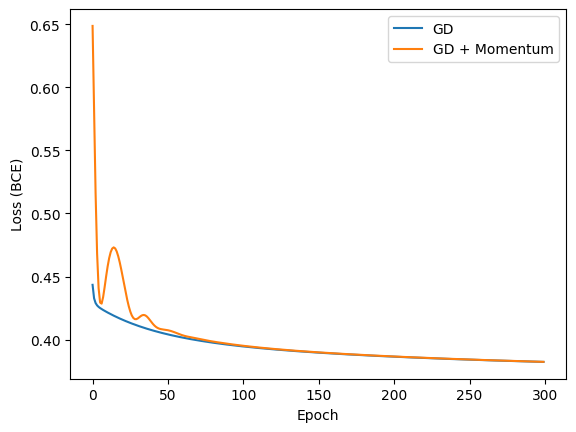

In [4]:
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, f1_score

p_rf = rf.predict_proba(X_test)[:, 1]
pred_rf = (p_rf >= 0.5).astype(int)
print("Random Forest (تصويت متساوي) - Test:",
      {"Loss": round(log_loss(y_test, p_rf), 4),
       "Accuracy": round(accuracy_score(y_test, pred_rf), 4),
       "Precision": round(precision_score(y_test, pred_rf), 4),
       "Recall": round(recall_score(y_test, pred_rf), 4),
       "F1": round(f1_score(y_test, pred_rf), 4)})

def gradient_descent(X, y, lr=0.1, epochs=300, beta=0.0):
    w = np.zeros((X.shape[1], 1))
    v = np.zeros_like(w)
    losses = []
    for _ in range(epochs):
        grad = X.T @ (sigmoid(X @ w) - y) / len(y)
        v = beta * v + grad
        w = w - lr * v
        losses.append(bce_loss(X, y, w))
    return w, losses

w_gd, loss_gd = gradient_descent(Xb_train, y_train, lr=0.1, beta=0.0)
w_gdm, loss_gdm = gradient_descent(Xb_train, y_train, lr=0.01, beta=0.9)

results = pd.DataFrame({
    "GD (Train)": evaluate(Xb_train, y_train, w_gd),
    "GD (Test)": evaluate(Xb_test, y_test, w_gd),
    "GD+Momentum (Train)": evaluate(Xb_train, y_train, w_gdm),
    "GD+Momentum (Test)": evaluate(Xb_test, y_test, w_gdm),
}).T.round(4)
print(results)

plt.plot(loss_gd, label="GD")
plt.plot(loss_gdm, label="GD + Momentum")
plt.xlabel("Epoch"); plt.ylabel("Loss (BCE)"); plt.legend(); plt.show()

# Learning Random Forest Tree Weights with Gradient Descent (and Momentum)

## الهدف
تطبيق Logistic Regression فوق مخرجات Random Forest للتنبؤ بنجاة ركاب Titanic (target: 1 نجا، 0 ما نجا). الـ Random Forest نفسه ما فيه أوزان بتتدرب بالـ gradient، فبنخلي الـ optimizer يتعلم وزن لكل شجرة بدل التصويت المتساوي، وبنقارن بين GD وGD مع momentum.

## البيانات
- داتا Titanic بعد التنظيف: 891 صف و7 features (Pclass, Sex, Age, SibSp, Parch, Fare, Embarked).
- حذفنا الصفوف اللي بدون labels حقيقية (الـ test الأصلي)، والأعمدة الثابتة، وعبينا قيمتين ناقصتين بعمود Embarked.
- قسمت البيانات: 80% تدريب (712 صف) و20% اختبار (179 صف) مع الحفاظ على نسبة الفئات (stratify).
- نسبة الناجين حوالي 38%، يعني الداتا غير متوازنة شوي.

## طريقة العمل
- بنينا Random Forest من 50 شجرة (max_depth = 5).
- لكل عينة طلعنا احتمال كل شجرة للـ class 1، فصار عندنا مصفوفة [عينات × 50 شجرة].
- للتدريب استخدمنا احتمالات الـ out-of-bag (الشجرة بتتنبأ بس للعينات اللي ما شافتها وقت بنائها) لتجنب overfitting، وللاختبار استخدمنا احتمالات الأشجار العادية.
- طبقنا StandardScaler على المصفوفة، وأضفنا عمود bias.
- النموذج: p = sigmoid(P @ w)، حيث w وزن كل شجرة، والتصنيف: 1 إذا p >= 0.5.
- الـ Loss: Binary Cross-Entropy، وقاعدة التحديث: v = beta * v + gradient ثم w = w - lr * v.
- المقاييس (محسوبة من الصفر من الـ confusion matrix): Accuracy و Precision و Recall و F1.

## الإعدادات
| الطريقة | learning rate | beta | epochs |
|---|---|---|---|
| GD | 0.1 | 0 | 300 |
| GD + Momentum | 0.01 | 0.9 | 300 |

## النتائج
| الطريقة | Loss | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Random Forest (تصويت متساوي) - Test | 0.4581 | 0.7933 | 0.8200 | 0.5942 | 0.6891 |
| GD (Train) | 0.3823 | 0.8343 | 0.8414 | 0.6996 | 0.7640 |
| GD (Test) | 0.4783 | 0.7821 | 0.7778 | 0.6087 | 0.6829 |
| GD+Momentum (Train) | 0.3823 | 0.8343 | 0.8414 | 0.6996 | 0.7640 |
| GD+Momentum (Test) | 0.4785 | 0.7821 | 0.7778 | 0.6087 | 0.6829 |

## الملاحظات
- منحنى GD العادي بدأ من loss حوالي 0.44 ونزل بشكل ناعم ووصل لحوالي 0.38 عند epoch 300 ولسا بينزل ببطء.
- منحنى الـ momentum بدأ من loss عالي (حوالي 0.65) ونزل بسرعة، وبعدين طلع مرة ثانية لحوالي 0.47 عند epoch 20 تقريباً، وصار فيه تذبذب صغير قبل ما يستقر. هاد الـ overshoot سببه إنه الـ velocity بيتجمع بالبداية فبيتجاوز الحل.
- بعد حوالي 100 epoch صار المنحنيان شبه متطابقين، لأن الـ learning rate الفعلي مع الـ momentum يساوي 0.01 / (1 - 0.9) = 0.1، نفس learning rate الـ GD العادي. وهاد سبب تطابق النتائج النهائية.
- الأوزان المتعلمة ما حسّنت على التصويت المتساوي: الـ Test Loss طلع 0.4783 مقابل 0.4581 للـ Random Forest العادي، والـ Accuracy 0.7821 مقابل 0.7933.
- الـ Precision (0.78) أعلى بكثير من الـ Recall (0.61)، يعني النموذج لما بيقول "نجا" بيكون غالباً صح، بس بيفوّت حوالي 39% من الناجين الحقيقيين. السبب الأساسي إنه الفئة الموجبة (الناجين) أقل من السالبة.
- الـ Test Loss (0.48) أعلى من الـ Train Loss (0.38)، والـ Accuracy نزلت من 0.83 لـ 0.78. في فجوة بين التدريب والاختبار، وحجم الاختبار صغير (179 عينة، وكل عينة بتغير الـ Accuracy بحوالي 0.56%).

## الخلاصة
تعلّم أوزان الأشجار بالـ GD أعطى Test Accuracy حوالي 78% وF1 حوالي 0.68، وهي نتيجة قريبة من الـ Random Forest العادي (79% و0.69) ما تفوقت عليه. الـ momentum ما غيّر النتيجة النهائية لأنه الـ learning rate الفعلي نفسه، بس غيّر شكل المنحنى بالبداية. الأشجار أصلاً بتتفق مع بعض بنسبة كبيرة، فتعلّم أوزان مختلفة إلها ما بيعطي مكسب كبير.